In [1]:
import pandas as pd

df = pd.read_csv(r'..\data\W158_select_nan_recode.csv')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   QKEY                  9593 non-null   int64  
 1   F_METRO               9585 non-null   float64
 2   F_CREGION             9585 non-null   float64
 3   F_CDIVISION           9585 non-null   float64
 4   F_USR_SELFID          9493 non-null   float64
 5   F_AGECAT              9555 non-null   float64
 6   F_GENDER              9561 non-null   float64
 7   F_EDUCCAT             9572 non-null   float64
 8   F_EDUCCAT2            9572 non-null   float64
 9   F_HISP                9565 non-null   float64
 10  F_RACECMB             9449 non-null   float64
 11  F_RACETHNMOD          9491 non-null   float64
 12  F_BIRTHPLACE          9551 non-null   float64
 13  F_MARITAL             9548 non-null   float64
 14  F_RELIG               9536 non-null   float64
 15  F_PARTY_FINAL         9534 non-n

In [2]:
dep_var_list = [
    'CONF_a_W158_r',
    'CONF_b_W158_r',
    'CONF_c_W158_r',
    'CONF_d_W158_r',
    'CONF_e_W158_r',
    'CONF_i_W158_r',
    'CONF_j_W158_r'
    ]

print(dep_var_list)

['CONF_a_W158_r', 'CONF_b_W158_r', 'CONF_c_W158_r', 'CONF_d_W158_r', 'CONF_e_W158_r', 'CONF_i_W158_r', 'CONF_j_W158_r']


In [3]:
# Dependent variable labels
dep_labels = {
    'CONF_a_W158_r': 'Elected officials',
    'CONF_b_W158_r': 'Journalists',
    'CONF_c_W158_r': 'The military',
    'CONF_d_W158_r': 'Religious leaders',
    'CONF_e_W158_r': 'Business leaders',
    'CONF_i_W158_r': 'Public school principals',
    'CONF_j_W158_r': 'Police officers',
    }

print(dep_labels)

{'CONF_a_W158_r': 'Elected officials', 'CONF_b_W158_r': 'Journalists', 'CONF_c_W158_r': 'The military', 'CONF_d_W158_r': 'Religious leaders', 'CONF_e_W158_r': 'Business leaders', 'CONF_i_W158_r': 'Public school principals', 'CONF_j_W158_r': 'Police officers'}


In [4]:
# Imputation and Scaling

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(df[dep_var_list])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

pd.DataFrame(X_scaled).describe()

,0,1,2,3,4,5,6
count,9.593000e+03,9.593000e+03,9.593000e+03,9.593000e+03,9.593000e+03,9.593000e+03,9593.000000
mean,3.496051e-16,-2.073929e-17,-1.066592e-16,1.659143e-16,-1.836908e-16,-1.762839e-16,0.000000
std,1.000052e+00,1.000052e+00,1.000052e+00,1.000052e+00,1.000052e+00,1.000052e+00,1.000052
min,-1.751441e+00,-1.544224e+00,-2.685711e+00,-1.820828e+00,-1.796884e+00,-2.387616e+00,-2.455138
25%,-3.145494e-01,-3.961389e-01,-1.277259e-01,-6.458512e-01,-4.265438e-01,-1.107969e+00,0.084998
50%,-3.145494e-01,-3.961389e-01,-1.277259e-01,5.291252e-01,-4.265438e-01,1.716778e-01,0.084998
75%,1.122342e+00,7.519459e-01,1.151267e+00,5.291252e-01,9.437961e-01,1.716778e-01,0.084998
max,2.559234e+00,1.900031e+00,1.151267e+00,1.704102e+00,2.314136e+00,1.451325e+00,1.355066


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Assumes X_scaled is a NumPy array or DataFrame
X = np.asarray(X_scaled)

Z = linkage(X, method="ward", metric="euclidean")

c, _ = cophenet(Z, pdist(X))
print(f"Cophenetic correlation: {c:.3f}")

Cophenetic correlation: 0.445


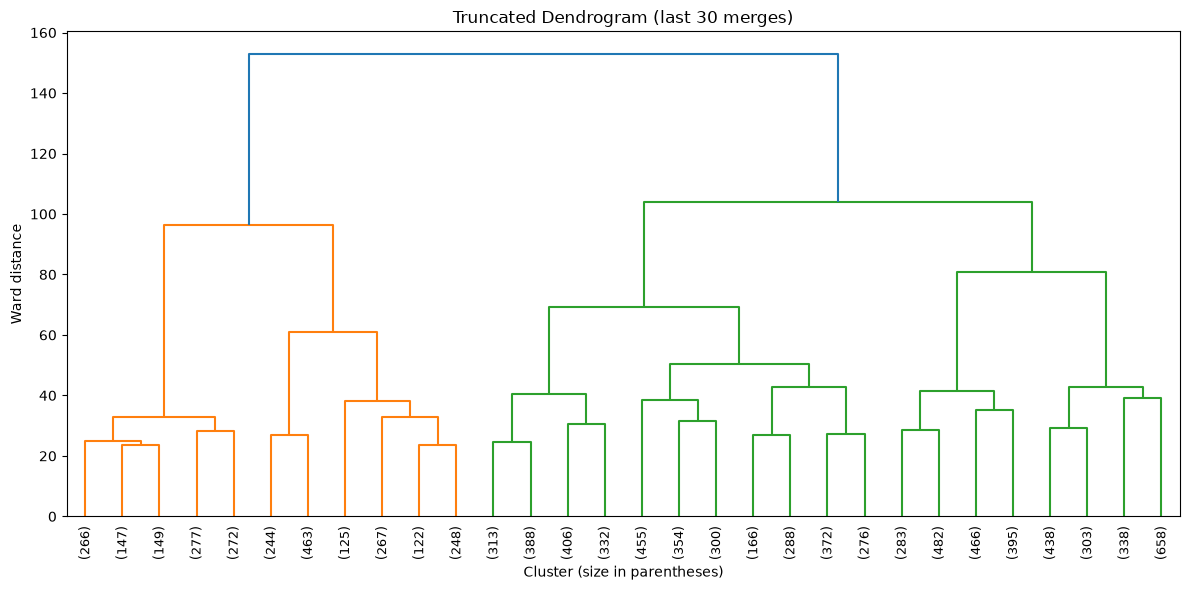

In [15]:
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True,
           leaf_rotation=90, leaf_font_size=9)
plt.title("Truncated Dendrogram (last 30 merges)")
plt.xlabel("Cluster (size in parentheses)")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

    k  silhouette
0   2    0.203323
1   3    0.109182
2   4    0.117012
3   5    0.104694
4   6    0.104344
5   7    0.100451
6   8    0.101002
7   9    0.085409
8  10    0.085233


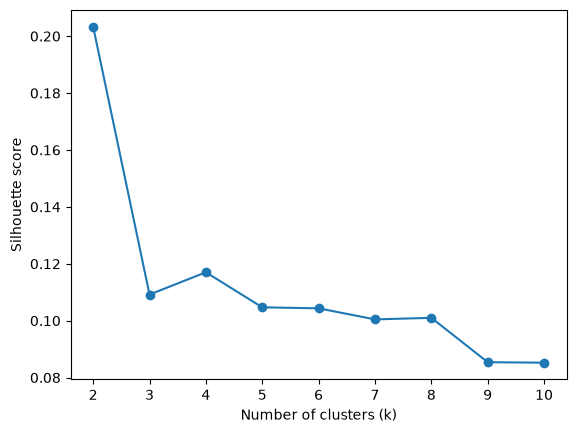

In [16]:
results = []
for k in range(2, 11):
    labels = fcluster(Z, t=k, criterion="maxclust")
    sil = silhouette_score(X, labels, sample_size=5000, random_state=42)
    results.append((k, sil))

res = pd.DataFrame(results, columns=["k", "silhouette"])
print(res)

plt.plot(res["k"], res["silhouette"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.show()

In [18]:
k = 5
labels = fcluster(Z, t=k, criterion="maxclust")

df = pd.DataFrame(X, columns=getattr(X_scaled, "columns", [f"f{i}" for i in range(X.shape[1])]))
df["cluster"] = labels

print(df["cluster"].value_counts().sort_index())
print(df.groupby("cluster").mean().round(2))

cluster
1    1111
2    1469
3    3650
4    1626
5    1737
Name: count, dtype: int64
           f0    f1    f2    f3    f4    f5    f6
cluster                                          
1       -0.42  0.21 -1.62 -0.80 -0.90 -0.02 -1.26
2       -0.93 -1.01 -0.46 -0.01 -0.27 -1.51 -0.25
3        0.12  0.30  0.18 -0.25 -0.41  0.29 -0.11
4       -0.42 -0.47  0.60  0.56  0.68  0.26  0.73
5        1.21  0.53  0.48  0.52  1.03  0.43  0.57


In [20]:
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

k = 5
Z = linkage(X_scaled, method="ward", metric="euclidean")
labels = fcluster(Z, t=k, criterion="maxclust") - 1      # shift to 0-based labels

mask = labels != -1                      # always all True for linkage; kept for parity with DBSCAN
n_clusters = len(set(labels[mask]))
sizes = np.bincount(labels[mask]) / len(labels) * 100   # % of total points
coph_corr, _ = cophenet(Z, pdist(X_scaled))

print(f"Clusters found:    {n_clusters}")
print(f"Noise fraction:    {(~mask).mean():.3f}")
print(f"Smallest cluster:  {sizes.min():.1f}% of total")
print(f"Largest cluster:   {sizes.max():.1f}% of total")
print(f"Silhouette:        {silhouette_score(X_scaled[mask], labels[mask]):.3f}")
print(f"Davies-Bouldin:    {davies_bouldin_score(X_scaled[mask], labels[mask]):.3f}")
print(f"Calinski-Harabasz: {calinski_harabasz_score(X_scaled[mask], labels[mask]):.1f}")

Clusters found:    5
Noise fraction:    0.000
Smallest cluster:  11.6% of total
Largest cluster:   38.0% of total
Silhouette:        0.105
Davies-Bouldin:    1.852
Calinski-Harabasz: 1418.8
